# Повторное обучение на CartPole-v1

Курсовая работа по МГМО. Горбунов Иван Олегович, ИУ6-74б.

Цель повторной серии — проверить, держат ли итоговые модели средний возврат
не ниже 475 на независимых стартах. Рассматриваются DQN, A3C, PPO и их варианты
с параметрическим шумом. Эксперименты на Acrobot остаются в ноутбуках
`02_final_study.ipynb` и `03_all_models.ipynb`.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / 'scripts/analyze_cartpole.py').is_file():
    root = root.parent
sys.path.insert(0, str(root / 'scripts'))
from analyze_cartpole import summarize, plot, THRESHOLD

groups, runs, curves = summarize(root / 'results')
out = root / 'results/cartpole_analysis'
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:.2f}')

## Исходная серия

В CartPole участвовали 20 запусков DQN/Noisy-DQN и 60 запусков A3C/PPO
с шумовыми модификациями. Остальные 60 запусков A3C/PPO относились к Acrobot.
Один DQN достиг 500 на валидации после 10 000 шагов, но затем потерял качество.
Оценка жадным выбором действий у части моделей PPO была выше стохастической.
Достижение порога последним чекпойнтом измеряется отдельно для каждого режима.
Первый шаг достижения определяется по основной валидационной кривой.

In [2]:
summary = pd.DataFrame([
    {'Модель': g['model'], 'Повторная серия': g['updated'],
     'Среднее': g['modes'][g['primary_mode']]['mean'],
     'SD': g['modes'][g['primary_mode']]['sd'],
     'Порог на валидации': g['validation_reached'],
     'Порог итоговой модели': g['modes'][g['primary_mode']]['solved']}
    for g in groups
])
display(summary.loc[~summary['Повторная серия']].drop(columns='Повторная серия'))

,Модель,Среднее,SD,Порог на валидации,Порог итоговой модели
0,DQN,139.88,51.07,1,0
2,Noisy-DQN,131.14,80.04,0,0
4,A3C,49.61,8.54,0,0
6,"Noisy-A3C, фактор.",49.17,4.11,0,0
8,"Noisy-A3C, незав.",48.10,6.94,0,0
10,PPO,146.07,32.56,0,0
12,"Noisy-PPO, фактор.",107.98,46.48,0,0
14,"Noisy-PPO, незав.",140.39,43.73,0,0


## Настройка и независимая проверка

Настройки выбирались на отдельных запусках. Манифесты настройки и финальной
серии находятся в `configs/cartpole_*`. В подтверждающей серии в каждом условии
десять обучений на seed 400–409. Валидационные старты 75 000–75 009,
итоговые 85 000–85 029. В итоговую таблицу входит последний чекпойнт каждого
обучения. Возврат в оценочной среде CartPole-v1 равен числу действий до
завершения эпизода или лимита 500. Выборочное SD вычисляется по средним
десяти моделей, каждая оценена на 30 эпизодах.

Для DQN основной режим использует средние веса. Для A3C и PPO основной режим
выбирает действие из распределения политики, а шумовые варианты используют
параметрический шум. Дополнительные режимы показаны отдельными строками.

Для повторной серии DQN использовалась тренировочная награда Sutton–Barto.
Она равна 0 за обычный шаг и −1 за выход за границы допустимого угла или позиции.
При истинном завершении эпизода длины T стандартный возврат
`G₊ = (1 − γᵀ)/(1 − γ)` и штрафной `G₋ = −γᵀ⁻¹` связаны
положительным аффинным преобразованием `G₋ = ((1 − γ)G₊ − 1)/γ`.
Это сохраняет порядок предпочтения траекторий при том же γ. При ограничении
длины эпизода остаётся bootstrap ценности следующего состояния.
Переход от жёсткого копирования целевой сети к мягкому обновлению и снижение
темпа обучения проверены вместе с изменением бюджета и replay. Обе серии
оценивались с обычной наградой +1. Разность возвратов характеризует изменение
всего протокола.

У A3C увеличен бюджет, а шаг Adam снижается от 0,003 до 0,0003 на последнем
интервале. Предел нормы градиента повышен до 40. Энтропийный бонус составляет
0,001 у обычного A3C и 0 у Noisy-A3C. Действия выбираются из распределения.
Повторный PPO использует раздельные сети политики и ценности, ортогональную
инициализацию и снижение шага Adam. Noisy-PPO использует один шум при сборе
траекторий и при вычислении отношения вероятностей в эпохах оптимизации.

Выбранный PPO использует 4 среды, rollout до 256 шагов каждой, 10 эпох,
minibatch 128 и clip-параметр 0,2 в суррогатной цели PPO. Энтропийный бонус
равен нулю во всех трёх условиях, σ₀ шумовых вариантов равен 0,01.

In [3]:
tuning = pd.read_csv(out / 'tuning.csv')
tuning = tuning[tuning['mode'].isin(['behaviour', 'mean_weights', 'resampled_noise'])]
display(tuning.groupby(['series', 'condition', 'mode'])['return_mean']
        .agg(запусков='size', среднее='mean', минимум='min').reset_index())

,series,condition,mode,запусков,среднее,минимум
0,cartpole_a3c_tuning,baseline_lr001,behaviour,1,96.80,96.80
1,cartpole_a3c_tuning,baseline_lr003_300k,behaviour,1,500.00,500.00
2,cartpole_a3c_tuning,baseline_lr003_500k,behaviour,2,500.00,500.00
3,cartpole_a3c_tuning,factorized_lr001,behaviour,1,103.50,103.50
4,cartpole_a3c_tuning,factorized_lr003_300k,behaviour,1,500.00,500.00
5,cartpole_a3c_tuning,factorized_lr003_500k,behaviour,2,500.00,500.00
6,cartpole_a3c_tuning,independent_lr001,behaviour,1,102.10,102.10
7,cartpole_a3c_tuning,independent_lr003_300k,behaviour,1,500.00,500.00
8,cartpole_a3c_tuning,independent_lr003_500k,behaviour,2,500.00,500.00
9,cartpole_dqn_tuning,cartpole/discount90_dqn,mean_weights,3,122.64,93.17


In [4]:
new = [g for g in groups if g['updated']]
settings = pd.DataFrame([
    {'Модель': g['model'], 'Шаги': g['config']['steps'],
     'Темп обучения': g['config']['learning_rate'], 'γ': g['config']['gamma'],
     'σ₀': g['config']['sigma0']}
    for g in new
])
display(settings.style.format({'Темп обучения': '{:.5f}', 'γ': '{:.3f}', 'σ₀': '{:.3f}'}))
display(pd.DataFrame([
    {'Модель': g['model'], 'Режим': mode, 'Среднее': s['mean'], 'SD': s['sd'],
     'Мин. по seed': s['min'], f'Моделей ≥ {THRESHOLD} из 10': s['solved']}
    for g in new for mode, s in g['modes'].items()
]))

,Модель,Шаги,Темп обучения,γ,σ₀
0,DQN,160000,0.00050,0.990,0.050
1,Noisy-DQN,160000,0.00050,0.990,0.050
2,A3C,500000,0.00300,0.990,0.100
3,"Noisy-A3C, фактор.",500000,0.00300,0.990,0.100
4,"Noisy-A3C, незав.",500000,0.00300,0.990,0.100
5,PPO,300000,0.00100,0.990,0.010
6,"Noisy-PPO, фактор.",300000,0.00100,0.990,0.010
7,"Noisy-PPO, незав.",300000,0.00100,0.990,0.010


,Модель,Режим,Среднее,SD,Мин. по seed,Моделей ≥ 475 из 10
0,DQN,mean_weights,463.17,116.46,131.73,9
1,Noisy-DQN,mean_weights,484.57,48.80,345.67,9
2,Noisy-DQN,resampled_noise,484.81,48.02,348.13,9
3,A3C,behaviour,500.00,0.00,500.00,10
4,A3C,mean_greedy,500.00,0.00,500.00,10
5,A3C,mean_sampled,500.00,0.00,500.00,10
6,"Noisy-A3C, фактор.",behaviour,497.10,6.14,484.47,10
7,"Noisy-A3C, фактор.",mean_greedy,500.00,0.00,500.00,10
8,"Noisy-A3C, фактор.",mean_sampled,500.00,0.00,500.00,10
9,"Noisy-A3C, незав.",behaviour,498.78,2.74,491.93,10


## Скорость и устойчивость

Первое достижение порога относится к контрольным точкам валидации.
Случаи недостижения учитываются в числе запусков. Медиана шага рассчитана
среди достигших. Длины бюджета и режимы различаются между семействами,
поэтому AUC и шаг достижения сравниваются внутри семейства.

На графиках линии обозначают средние, заливка — одно выборочное стандартное
отклонение между запусками. Полоса SD может выходить за предел 500.
Итоговая оценка на новых стартах приведена в таблицах.
У PPO на первой проверенной точке (50 000 шагов) возвраты лежат в диапазоне
496,8–500. На итоговой оценке все три варианта достигают лимита 500,
который ограничивает различимость их качества в этом эксперименте.

,Модель,Достигли на валидации,Последняя валидация ≥475,Медиана первого шага,AUC / бюджет
0,DQN,10,9,60000.00,371.33
1,Noisy-DQN,10,9,55000.00,391.38
2,A3C,10,10,150000.00,392.35
3,"Noisy-A3C, фактор.",10,10,200000.00,396.40
4,"Noisy-A3C, незав.",10,10,175000.00,411.12
5,PPO,10,10,50000.00,460.31
6,"Noisy-PPO, фактор.",10,10,50000.00,460.43
7,"Noisy-PPO, незав.",10,10,50000.00,460.27


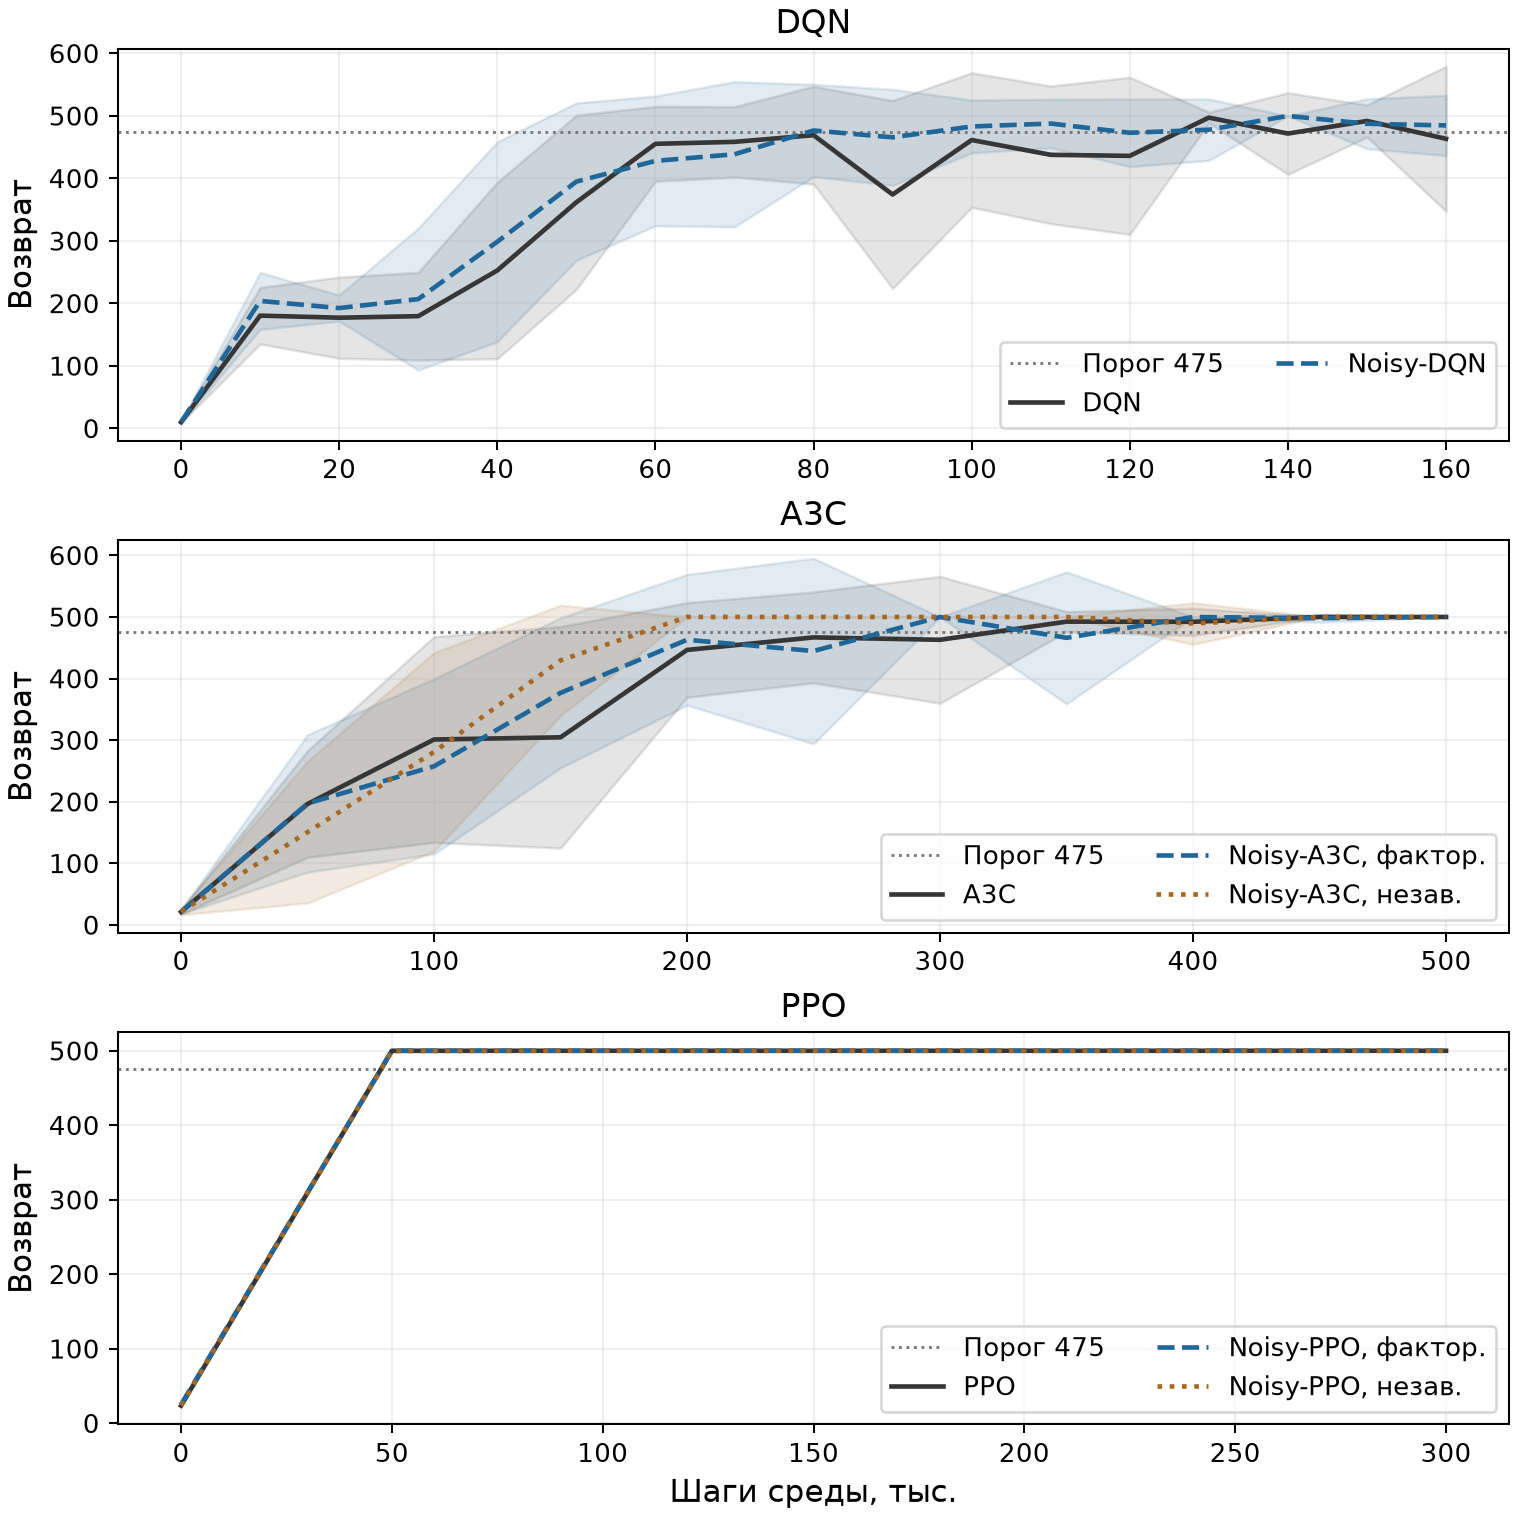

In [5]:
display(pd.DataFrame([
    {'Модель': g['model'], 'Достигли на валидации': g['validation_reached'],
     'Последняя валидация ≥475': g['validation_final_reached'],
     'Медиана первого шага': g['median_first_step'], 'AUC / бюджет': g['validation_auc']}
    for g in new
]))
plot(groups, curves, out / 'learning.png')
display(Image(filename=str(out / 'learning.png')))

## Результаты по каждому обучению

Ниже приведены все итоговые значения основного режима. Журналы эпизодов и
сохранённые модели лежат в `results/cartpole_*_final`. Скрипт
`scripts/verify_cartpole.py` повторно оценивает чекпойнты и сравнивает
награду, длину и признаки завершения каждого эпизода с журналом.

In [6]:
primary = {(g['model'], g['primary_mode']) for g in new}
rows = [r for r in runs if r['series'] == 'tuned' and (r['model'], r['mode']) in primary]
display(pd.DataFrame(rows).pivot(index='seed', columns='model', values='return_mean'))

model,A3C,DQN,"Noisy-A3C, незав.","Noisy-A3C, фактор.",Noisy-DQN,"Noisy-PPO, незав.","Noisy-PPO, фактор.",PPO
seed,,,,,,,,
400,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
401,500.00,131.73,500.00,484.47,500.00,500.00,500.00,500.00
402,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
403,500.00,500.00,500.00,486.50,500.00,500.00,500.00,500.00
404,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
405,500.00,500.00,495.83,500.00,500.00,500.00,500.00,500.00
406,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
407,500.00,500.00,500.00,500.00,500.00,500.00,500.00,500.00
408,500.00,500.00,491.93,500.00,345.67,500.00,500.00,500.00


In [7]:
verification = json.loads((out / 'checkpoint_verification.json').read_text())
assert verification['all_verified'] and verification['verified_models'] == 80
assert (verification['verified_model_modes'], verification['verified_episodes']) == (200, 6000)
display(pd.DataFrame([{
    'Чекпойнтов проверено': verification['verified_models'],
    'Пар модель / режим': verification['verified_model_modes'],
    'Совпавших эпизодов': verification['verified_episodes'],
}]))

,Чекпойнтов проверено,Пар модель / режим,Совпавших эпизодов
0,80,200,6000


## Остановка DQN по валидации

Чтобы проверить, помогает ли остановка сохранить уже найденную политику,
обучены новые модели на seed 410–419. Стартовые состояния для решения об
остановке имеют seed 76 050–76 059, для итоговой проверки — 86 000–86 029.
Обучение прекращается после двух последовательных средних оценок ≥475,
для Noisy-DQN в обоих режимах, или по достижении 160 000 шагов.
В итоговую таблицу входят все новые модели.

In [8]:
stopping_dir = root / 'results/cartpole_dqn_stopping/analysis'
stopping = json.loads((stopping_dir / 'summary.json').read_text())
assert stopping['exact_checkpoint_verification']['all_match']
display(pd.DataFrame([
    {'Модель': g['condition'], 'Режим': mode, 'Среднее': s['mean'], 'SD': s['sample_sd'],
     'Моделей ≥475': s['models_ge475'], 'Медиана шагов': g['actual_steps']['median']}
    for g in stopping['conditions'] for mode, s in g['modes'].items()
]))
display(pd.read_csv(stopping_dir / 'runs.csv'))

,Модель,Режим,Среднее,SD,Моделей ≥475,Медиана шагов
0,dqn,mean_weights,498.75,3.96,10,70000.00
1,noisy,mean_weights,499.83,0.55,10,75000.00
2,noisy,resampled_noise,499.20,1.81,10,75000.00


,condition,seed,actual_steps,step_cap,stop_reason,stopped_before_cap,gradient_updates,final_validation_mean,final_validation_stochastic_mean,mean_weights,resampled_noise,all_modes_ge475,folder
0,dqn,410,70000,160000,validation_threshold,True,34751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
1,dqn,411,70000,160000,validation_threshold,True,34751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
2,dqn,412,60000,160000,validation_threshold,True,29751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
3,dqn,413,60000,160000,validation_threshold,True,29751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
4,dqn,414,70000,160000,validation_threshold,True,34751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
5,dqn,415,70000,160000,validation_threshold,True,34751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
6,dqn,416,100000,160000,validation_threshold,True,49751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
7,dqn,417,90000,160000,validation_threshold,True,44751,478.00,NaN,487.47,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
8,dqn,418,80000,160000,validation_threshold,True,39751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
9,dqn,419,60000,160000,validation_threshold,True,29751,500.00,NaN,500.00,NaN,True,results/cartpole_dqn_stopping/cartpole/dqn/see...
